--- Checking for Missing Values ---
annual_income            29959
customer_satisfaction    19921
num_complaints           29906
avg_monthly_gb           50012
credit_score             40395
dtype: int64

--- Identifying Categorical Variables ---
Categorical Columns: ['customer_id', 'signup_date', 'gender', 'education', 'marital_status', 'contract', 'payment_method', 'paperless_billing']

--- Checking Churn Imbalance ---
Churn Counts:
churn
0    900773
1     99227
Name: count, dtype: int64

Churn Proportions (%):
churn
0    90.0773
1     9.9227
Name: proportion, dtype: float64


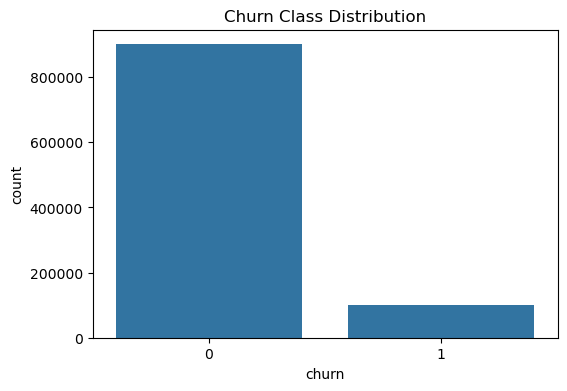


--- Executing Data Cleaning ---


C:\Users\bhato\AppData\Local\Temp\ipykernel_16284\2831633441.py:55: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean[col].fillna(df_clean[col].mode()[0], inplace=True)
C:\Users\bhato\AppData\Local\Temp\ipykernel_16284\2831633441.py:58: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

Data cleaned successfully. Current shape: (1000000, 30)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset (replace with your actual filename)
df = pd.read_csv('G:\\Ethans\\Internship\\week 10\\data\\dirty\\customer_churn_1M.csv')

# ==========================================
# Phase 1: EDA & Checks
# ==========================================

print("--- Checking for Missing Values ---")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

print("\n--- Identifying Categorical Variables ---")
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print("Categorical Columns:", categorical_cols)

print("\n--- Checking Churn Imbalance ---")
# Assuming the target column is named 'churn' as seen in the image
churn_counts = df['churn'].value_counts()
churn_props = df['churn'].value_counts(normalize=True) * 100
print(f"Churn Counts:\n{churn_counts}")
print(f"\nChurn Proportions (%):\n{churn_props}")

# Plotting the imbalance
plt.figure(figsize=(6, 4))
sns.countplot(x='churn', data=df)
plt.title('Churn Class Distribution')
plt.show()

# ==========================================
# Phase 2: Data Cleaning
# ==========================================

def clean_customer_data(dataframe):
    df_clean = dataframe.copy()
    
    # 1. Drop irrelevant identifier columns (looks like 'customer_' is an ID)
    cols_to_drop = [col for col in df_clean.columns if 'customer_' in col.lower()]
    df_clean = df_clean.drop(columns=cols_to_drop, errors='ignore')
    
    # 2. Handle Date Columns (e.g., 'signup_dat')
    if 'signup_dat' in df_clean.columns:
        # Option A: Drop it if you are using 'tenure' instead
        df_clean = df_clean.drop(columns=['signup_dat'])
        # Option B: Convert to datetime if you want to extract features
        # df_clean['signup_dat'] = pd.to_datetime(df_clean['signup_dat'])
    
    # 3. Handle Missing Values
    for col in df_clean.columns:
        if df_clean[col].dtype == 'object':
            # Fill missing categoricals with the mode (most frequent value)
            df_clean[col].fillna(df_clean[col].mode()[0], inplace=True)
        else:
            # Fill missing numericals with the median to avoid outlier skew
            df_clean[col].fillna(df_clean[col].median(), inplace=True)
            
    # 4. Standardize text data (optional but recommended)
    categorical_cols = df_clean.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        df_clean[col] = df_clean[col].str.lower().str.strip()
        
    return df_clean

print("\n--- Executing Data Cleaning ---")
df_cleaned = clean_customer_data(df)
print("Data cleaned successfully. Current shape:", df_cleaned.shape)


# You can now pass df_cleaned into the transformation pipeline!

In [4]:
df_cleaned.to_csv('G:\\Ethans\\Internship\\week 10\\data\\clean\\customer_churn_cleaned.csv', index=False)